# Fitting the exponential map to experimental grid cells

Reproduces Fig. 9 and Fig. 10 (Appendix K). This is the **one place** in the framework
where anything is learned by gradient descent — everywhere else the generators are built
algebraically from an eigenvalue specification.

The question is whether real grid cell ratemaps are consistent with an exponential map at
all, and if so whether the recovered generators say anything beyond the arena they were
fitted in. So the fit minimises the one-step prediction error of Eq. 1 over random
displacements,

$$L = \big\langle \|p(r + \delta r) - e^{\delta x G_x + \delta y G_y}p(r)\|^2 \big\rangle
      + w\,\|[G_x, G_y]\|^2$$

and is then asked to generate the arena it saw (Fig. 9b) and one **twice as large**
(Fig. 9c). Nothing in training used displacements that large, so the extrapolation is a
genuine prediction: the periodic pattern continues past the training boundary, drawn as a
black outline.

**What is imposed.** The commutator penalty is what makes the solution path-integrating
rather than merely a good interpolator — without it, displacements need not compose.
Skew-symmetry is imposed *structurally*, by learning $A$ and taking $G = A - A^\top$, as
Appendix K does "to guarantee orthogonal transport during spatial extrapolation": only an
orthogonal $e^{\delta r \cdot G}$ keeps $\|p\|$ from drifting once the displacements leave
the range the fit ever saw. The last cell contrasts it against a freely parameterised fit,
which is where that matters.

The optimiser lives in `expmap.fitting`, with `tests/test_fitting.py` checking on
synthetic data that it recovers transport, extrapolates, and that the penalty does drive
the generators to commute.

**Data.** `data/gc_ratmaps.npy` — 102 units, 32×32 bins, rate in arbitrary units
(≈ 0–0.2). The arena is taken as $[-1, 1]$, so one pixel is $2/32$.

In [1]:
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.fitting import GeneratorFit, generator_diagnostics
from expmap.plotting import ratemap_collage

# Fit parameters. N_STEPS = 20000 is the published training length.
N_STEPS = 20000
BATCH_SIZE = 32
MAX_STEP = 2  # largest pixel step per axis
LR = 1e-3
COMMUTATOR_WEIGHT = 1.0
ARENA_SIZE = 1.0  # experimental maps span [-1, 1], so one pixel is 2/32
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
DATA = REPO_ROOT / "data" / "gc_ratmaps.npy"

102 units, 32 x 32 bins, rate range 0.0001..0.1999


(np.float64(-0.5), np.float64(31.5), np.float64(-0.5), np.float64(31.5))

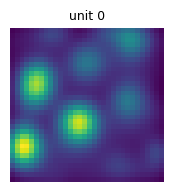

In [2]:
# Stored as (n_units, bins_x, bins_y); the fit wants position first so a pixel index
# returns a population vector.
experimental = np.load(DATA).astype("float32")
ratemaps = torch.tensor(np.transpose(experimental, (1, 2, 0)))

N_UNITS = experimental.shape[0]
N_BINS = experimental.shape[1]
print(f"{N_UNITS} units, {N_BINS} x {N_BINS} bins, rate range {experimental.min():.4f}..{experimental.max():.4f}")

plt.figure(figsize=(2, 2))
plt.imshow(experimental[0].T, origin="lower")
plt.title("unit 0", fontsize=9)
plt.axis("off")

In [3]:
fit = GeneratorFit(
    n_units=N_UNITS,
    commutator_weight=COMMUTATOR_WEIGHT,
    lr=LR,
    seed=SEED,
)
loss_history = fit.fit(
    ratemaps,
    n_steps=N_STEPS,
    batch_size=BATCH_SIZE,
    max_step=MAX_STEP,
    arena_size=ARENA_SIZE,
)
print(f"loss {np.mean(loss_history[:100]):.3e} -> {np.mean(loss_history[-100:]):.3e}")

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 4/20000 [00:00<08:38, 38.56it/s]

  0%|          | 9/20000 [00:00<07:46, 42.90it/s]

  0%|          | 14/20000 [00:00<07:37, 43.70it/s]

  0%|          | 19/20000 [00:00<07:35, 43.89it/s]

  0%|          | 24/20000 [00:00<07:27, 44.65it/s]

... (4,288 outputs left out)

100%|█████████▉| 19995/20000 [08:29<00:00, 39.71it/s]

100%|██████████| 20000/20000 [08:30<00:00, 40.16it/s]

100%|██████████| 20000/20000 [08:30<00:00, 39.22it/s]

loss 8.988e-04 -> 5.250e-05


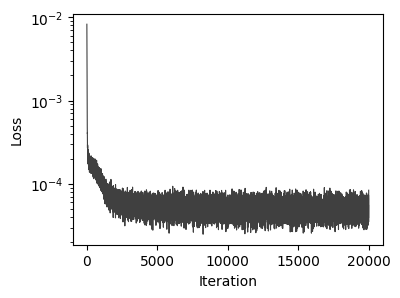

In [4]:
# Fig. 10: the optimisation curve.
plt.figure(figsize=(4, 3))
plt.semilogy(loss_history, "k", linewidth=0.8, alpha=0.75)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.savefig(FIGURE_DIR / "experimental_loss_curve.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "experimental_loss_curve.png", dpi=300, bbox_inches="tight")

In [5]:
# Generate from the population vector at the arena centre: the same domain the fit saw,
# and one twice as wide. Both are indexed (unit, bins_x, bins_y), like the experimental
# maps, so the three rows of Fig. 9 line up cell-to-cell.
centre = ratemaps[N_BINS // 2, N_BINS // 2]
generated_same = fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()
generated_double = fit.generate(centre, n_bins=N_BINS, extent=2.0, arena_size=ARENA_SIZE).numpy()

print(f"generated: {generated_same.shape}, extrapolated: {generated_double.shape}")

generated: (102, 32, 32), extrapolated: (102, 32, 32)


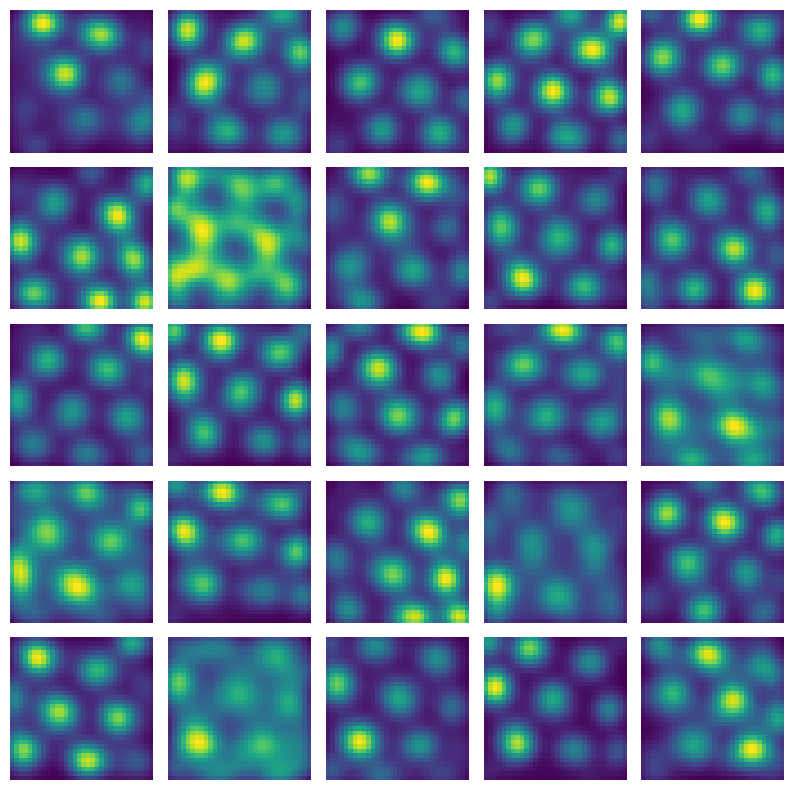

In [6]:
# Fig. 9a: the experimental ratemaps the fit was trained on.
fig, _ = ratemap_collage(experimental, rows=5, cols=5, figsize=(10, 10))
fig.savefig(FIGURE_DIR / "experimental_ratemaps.svg", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "experimental_ratemaps.png", dpi=300, bbox_inches="tight")

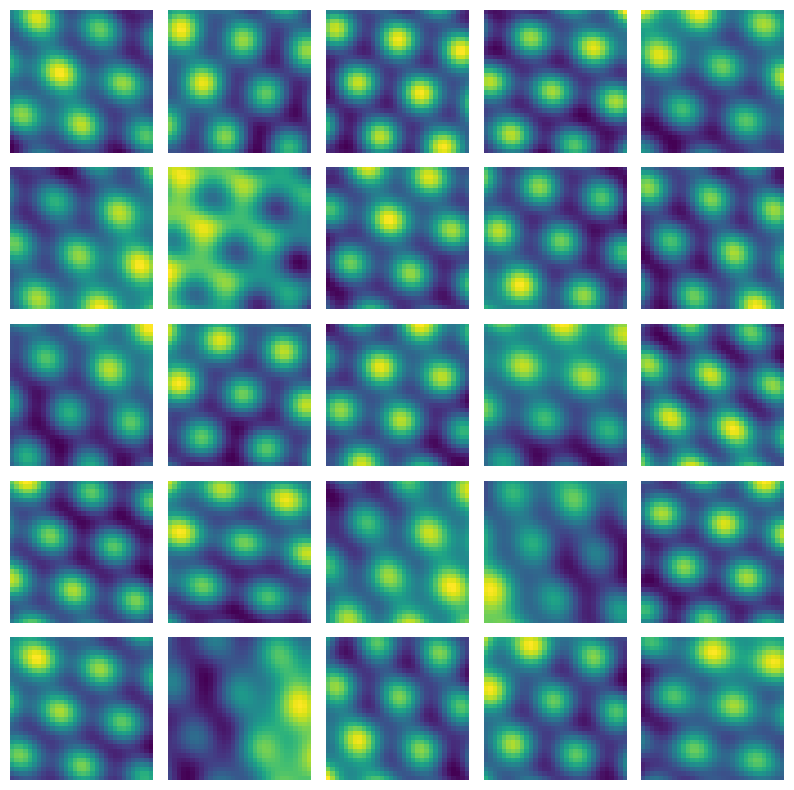

In [7]:
# Fig. 9b: the same units regenerated within the training domain.
fig, _ = ratemap_collage(generated_same, rows=5, cols=5, figsize=(10, 10))
fig.savefig(FIGURE_DIR / "generated_ratemaps_same_size.svg", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "generated_ratemaps_same_size.png", dpi=300, bbox_inches="tight")

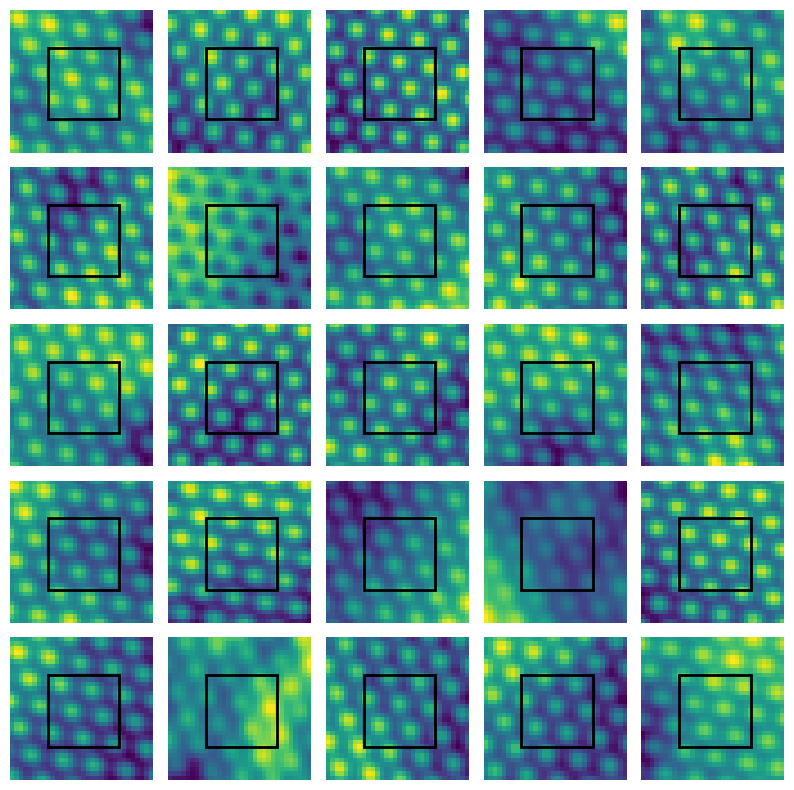

In [8]:
# Fig. 9c: the extrapolation. The black outline is the training domain — the central half
# of each panel. Everything outside it uses displacements the fit never saw.
fig, axs = ratemap_collage(generated_double, rows=5, cols=5, figsize=(10, 10))

for ax in axs.ravel():
    ax.add_patch(
        patches.Rectangle(
            (N_BINS // 4, N_BINS // 4), N_BINS // 2, N_BINS // 2,
            linewidth=2, edgecolor="k", facecolor="none",
        )
    )

fig.savefig(FIGURE_DIR / "generated_ratemaps_double_size.svg", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "generated_ratemaps_double_size.png", dpi=300, bbox_inches="tight")

RMS residual 0.0148 vs data RMS 0.0409
relative reconstruction error: 36.3%


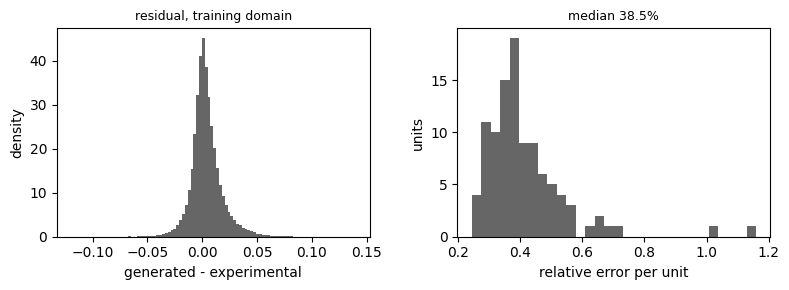

In [9]:
# Reconstruction error, comparing like with like: the *same-size* generation against the
# experimental maps. (The original notebook differenced the doubled-arena generation
# against the originals, which compares two different spatial extents.)
residual = generated_same - experimental
relative = np.sqrt(np.mean(residual**2)) / np.sqrt(np.mean(experimental**2))
print(f"RMS residual {np.sqrt(np.mean(residual**2)):.4f} vs data RMS {np.sqrt(np.mean(experimental**2)):.4f}")
print(f"relative reconstruction error: {relative:.1%}")

fig, axs = plt.subplots(1, 2, figsize=(8, 3))
axs[0].hist(residual.ravel(), bins=100, density=True, color="0.4")
axs[0].set_xlabel("generated - experimental")
axs[0].set_ylabel("density")
axs[0].set_title("residual, training domain", fontsize=9)

per_unit = np.sqrt(np.mean(residual**2, axis=(1, 2))) / np.sqrt(np.mean(experimental**2, axis=(1, 2)))
axs[1].hist(per_unit, bins=30, color="0.4")
axs[1].set_xlabel("relative error per unit")
axs[1].set_ylabel("units")
axs[1].set_title(f"median {np.median(per_unit):.1%}", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experimental_residuals.svg", dpi=300, bbox_inches="tight")

  commutator_rms             3.9653e-04
  Gx_rms                     1.8459e-01
  Gx_symmetric_fraction      0.0000e+00
  Gy_rms                     1.6875e-01
  Gy_symmetric_fraction      0.0000e+00
  ||p||, training domain: 0.4565 +/- 1.72e-07
  ||p||, doubled arena  : 0.4565 +/- 3.29e-07


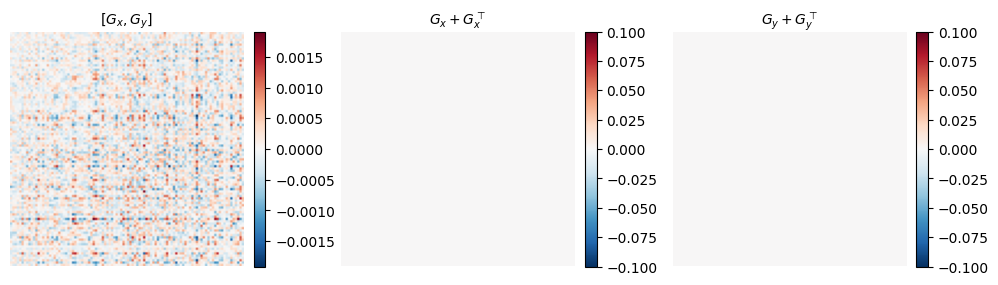

In [10]:
# What did the fit recover, and why does App. K reparameterise?
#
# The commutator was penalised, so it should be small - that is the path-integration
# condition. Skew-symmetry is structural here, so its symmetric fraction is 0 by
# construction; the free-parameterisation fit below is the comparison that shows the cost.
diagnostics = generator_diagnostics(fit)
for name, value in diagnostics.items():
    print(f"  {name:26s} {value:.4e}")

# Orthogonal transport preserves ||p|| everywhere, including out in the extrapolated
# region that no training displacement ever reached.
for label, maps in [("training domain", generated_same), ("doubled arena", generated_double)]:
    norms = np.linalg.norm(maps.reshape(N_UNITS, -1), axis=0)
    print(f"  ||p||, {label:15s}: {norms.mean():.4f} +/- {norms.std():.2e}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3))
commutator = (fit.Gx @ fit.Gy - fit.Gy @ fit.Gx).detach().numpy()
for ax, matrix, title in [
    (axs[0], commutator, r"$[G_x, G_y]$"),
    (axs[1], (fit.Gx + fit.Gx.T).detach().numpy(), r"$G_x + G_x^\top$"),
    (axs[2], (fit.Gy + fit.Gy.T).detach().numpy(), r"$G_y + G_y^\top$"),
]:
    im = ax.imshow(matrix, cmap="RdBu_r")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experimental_generator_structure.svg", dpi=300, bbox_inches="tight")

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 5/20000 [00:00<07:42, 43.27it/s]

  0%|          | 10/20000 [00:00<07:08, 46.62it/s]

  0%|          | 16/20000 [00:00<06:54, 48.26it/s]

  0%|          | 21/20000 [00:00<06:54, 48.25it/s]

  0%|          | 26/20000 [00:00<07:00, 47.52it/s]

... (4,011 outputs left out)

100%|█████████▉| 19995/20000 [08:01<00:00, 39.78it/s]

100%|██████████| 20000/20000 [08:01<00:00, 39.83it/s]

100%|██████████| 20000/20000 [08:01<00:00, 41.55it/s]

final loss   enforced 5.250e-05   free 3.103e-05
Gx symmetric fraction   enforced 0.00e+00   free 0.880


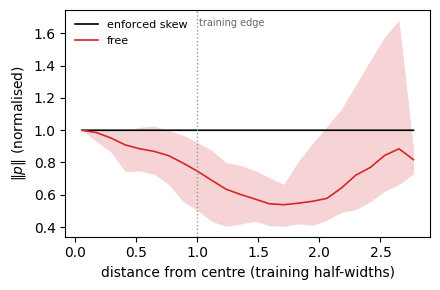

In [11]:
# The comparison App. K's sentence implies: fit the same data without enforcing skew.
# It reaches a similar training loss, but transport is no longer orthogonal, so ||p||
# drifts as soon as the extrapolation leaves the fitted arena.
free_fit = GeneratorFit(
    n_units=N_UNITS,
    commutator_weight=COMMUTATOR_WEIGHT,
    lr=LR,
    enforce_skew=False,
    seed=SEED,
)
free_fit.fit(ratemaps, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=ARENA_SIZE)

free_same = free_fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()
free_double = free_fit.generate(centre, n_bins=N_BINS, extent=2.0, arena_size=ARENA_SIZE).numpy()

print(f"final loss   enforced {np.mean(loss_history[-100:]):.3e}   free {np.mean(free_fit.loss_history[-100:]):.3e}")
print(f"Gx symmetric fraction   enforced {generator_diagnostics(fit)['Gx_symmetric_fraction']:.2e}"
      f"   free {generator_diagnostics(free_fit)['Gx_symmetric_fraction']:.3f}")

# ||p|| against distance from the arena centre, both fits. Many pixels share a radius, so
# bin and show the mean with a min-max band rather than one line through every pixel.
axis = np.arange(N_BINS) - N_BINS // 2
radius = np.sqrt(axis[:, None] ** 2 + axis[None, :] ** 2).ravel() * 2 * 2 / N_BINS
edges = np.linspace(0, radius.max(), 25)
centres = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(4.5, 3))
for maps, label, colour in [(generated_double, "enforced skew", "k"), (free_double, "free", "C3")]:
    norms = np.linalg.norm(maps.reshape(N_UNITS, -1), axis=0)
    norms = norms / norms[np.argmin(radius)]
    binned = [norms[(radius >= lo) & (radius < hi)] for lo, hi in zip(edges[:-1], edges[1:])]
    keep = [i for i, values in enumerate(binned) if len(values)]
    mean = np.array([binned[i].mean() for i in keep])
    lo = np.array([binned[i].min() for i in keep])
    hi = np.array([binned[i].max() for i in keep])
    plt.fill_between(centres[keep], lo, hi, color=colour, alpha=0.2, linewidth=0)
    plt.plot(centres[keep], mean, color=colour, linewidth=1.2, label=label)
plt.axvline(1.0, color="0.6", linewidth=1, linestyle=":")
plt.text(1.02, plt.ylim()[1] * 0.97, "training edge", fontsize=7, va="top", color="0.4")
plt.xlabel("distance from centre (training half-widths)")
plt.ylabel(r"$\|p\|$ (normalised)")
plt.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "experimental_norm_drift.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "experimental_norm_drift.png", dpi=300, bbox_inches="tight")